In [2]:
import geopandas as gpd
import sys
sys.path.append("../Functions")

%load_ext autoreload
%autoreload 2

from GSC_funcs import *

In [3]:
fp = gpd.read_file("../Data/selected_perimeters.gpkg")

In [4]:
aoi_bb = [-8.38, 39.78, -7.72, 40.2]

# Here we can select which bands we are interested in using.
bands = [
    # 'coastal',  # band 1, coastal/aerosol
    'blue',  # band 2, blue
    'green',  # band 3, green
    'red',  # band 4, red
    'nir08',  # band 5, near-infrared
    'swir16',  # band 6, shortwave infrared 1
    'swir22',  # band 7, shortwave infrared 2
]

catalog = connect_MPC()

In [5]:
from datetime import datetime, timedelta

start_date = datetime(2017, 6, 1)
end_date = datetime(2017, 8, 1)
period = 7 # in days

date_ranges_A = date_ranges(start_date, end_date, period)
print(date_ranges_A)

['2017-06-02/2017-06-08', '2017-06-09/2017-06-15', '2017-06-16/2017-06-22', '2017-06-23/2017-06-29', '2017-06-30/2017-07-06', '2017-07-07/2017-07-13', '2017-07-14/2017-07-20', '2017-07-21/2017-07-27', '2017-07-28/2017-08-03']


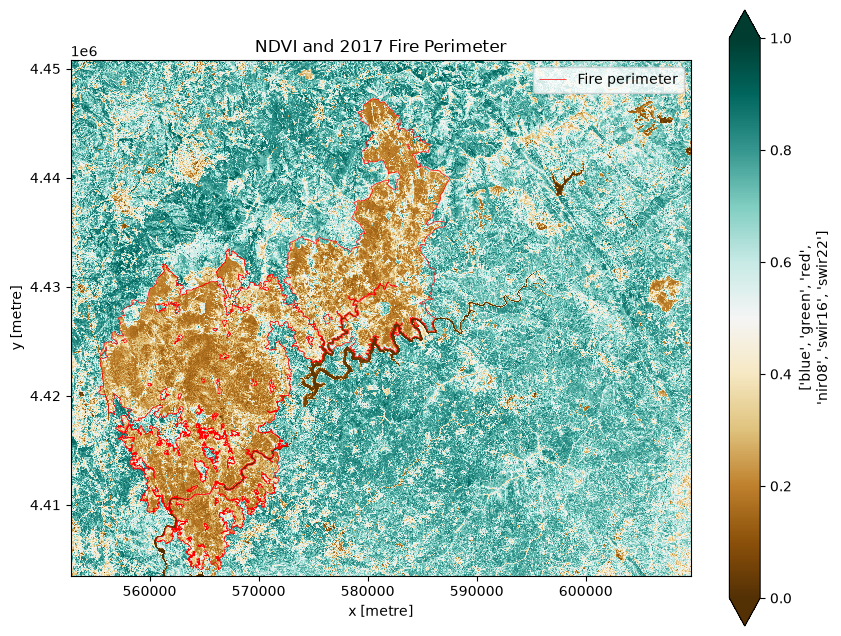

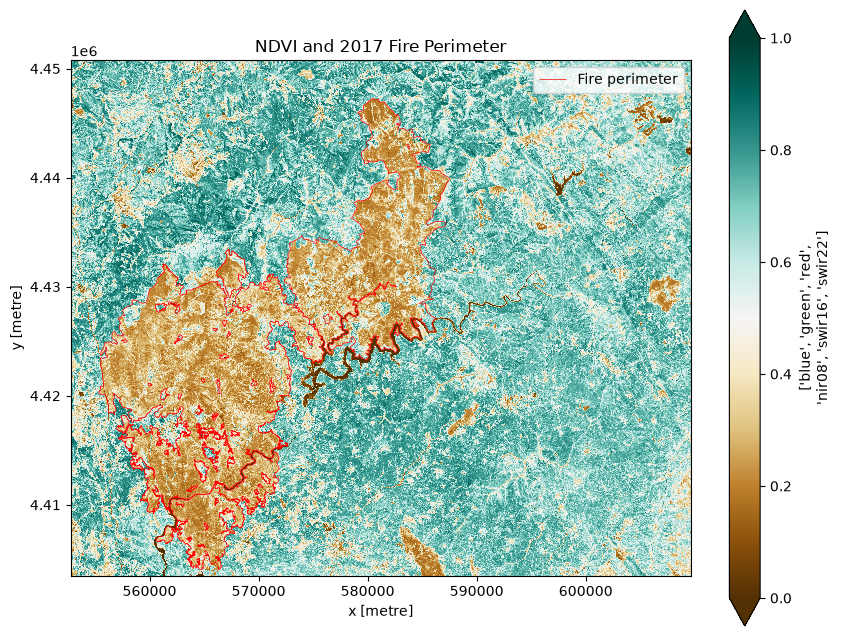

In [6]:
#rngs = len(date_ranges_A)
#prop = 0
for rng in date_ranges_A:
    items = search_Landsat(aoi_bb, rng, 10, catalog)
    if len(items) != 0:
        filtered_items = filter_items(aoi_bb, items, 0.7)
        if len(filtered_items) != 0:
            ds = load_scene(filtered_items[0], bands, aoi_bb)
            # Calculate NDVI
            normalised_index = ndvi(ds)
            
            # Create figure and axes
            fig, ax = plt.subplots(figsize=(10, 8))
            
            # Plot NDVI
            normalised_index.plot.imshow(
                ax=ax,
                cmap="BrBG",
                robust=True,
                vmin=0,
                vmax=1,
                add_colorbar=True
            )
            
            # Reproject fire perimeter to match Landsat CRS
            fp_landsat = fp.to_crs(ds.rio.crs)
            
            # Overlay perimeter
            fp_landsat.boundary.plot(
                ax=ax,
                color="red",
                linewidth=0.5,
                label="Fire perimeter"
            )
            
            ax.set_title("NDVI and 2017 Fire Perimeter")
            ax.legend()
            
            plt.show()
            
    #prop = prop + 1
    #print(str(round((prop/rngs)*100))+"%")